<a href="https://colab.research.google.com/github/VidhiSidana/UCS420/blob/main/assignment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170410         # <-- your full roll number
NAME = "Vidhi Sidana"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170410   Name: Vidhi Sidana   Fingerprint: 88F8BE23   Tickets: 12

Ticket_ID                                                                              Ticket_Text
      T01                   I can't open the printer while uploading the file. Can you check this?
      T02                                              The state-of-the-art lab (Lab-3) is closed.
      T03                                    The student portal failed to open. Please resolve it.
      T04                                                   Only 2 of 30 PCs boot after 3.5 hours.
      T05                                                    The Wi-Fi works, but the VPN doesn't.
      T06    I am unable to use the e-mail after restarting the system. Is there another solution?
      T07 I keep getting logged out of the projector when I use mobile hotspot. Please resolve it.
      T08         I can't open the e-mail while uploading the file. The same problem occurs again.
      T09                

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:

results = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    result = process_ticket(text)

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

q1_df = pd.DataFrame(results)

# Add a TOTAL row for count-based columns.
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation Tokens": q1_df["Punctuation Tokens"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique Tokens": len(set(
        token
        for text in df["Ticket_Text"]
        for token in process_ticket(text)["tokens"]
    )),
    "Final Tokens": q1_df["Final Tokens"].sum()
}

q1_df = pd.concat(
    [q1_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_df)


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,16,2,7,15,7
1,T02,1,9,3,2,9,4
2,T03,2,11,2,3,10,6
3,T04,1,10,1,3,10,6
4,T05,1,10,2,4,9,4
5,T06,2,17,2,8,16,7
6,T07,2,18,2,7,16,9
7,T08,2,17,2,7,14,8
8,T09,1,9,1,3,9,5
9,T10,2,11,2,4,11,5


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*Some final tokens are not complete English words, such as `n't`, `'s`, and `ca`. These tokens can come from contractions like “isn't,” “didn't,” and “can't.” NLTK's `word_tokenize()` splits contractions into separate parts, and the preprocessing pipeline keeps tokens that are neither punctuation nor stopwords. As a result, contraction fragments may remain in the final tokens.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
patterns = {
    "Words longer than 5 letters":
        r"\b[A-Za-z]{6,}\b",
    "Numbers":
        r"\b\d+(?:\.\d+)+\b|\b\d+\b",

    "Capitalized words":
        r"\b[A-Z][a-zA-Z]*\b",

    "Words starting with a vowel":
        r"\b[aeiouAEIOU][a-zA-Z]*\b"
}

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTEST LINE {i}")
    for name, pattern in patterns.items():
        print(f"{name}: {re.findall(pattern, line)}")
def replace_patterns(text):
    # URLs
    text = re.sub(
        r"https?://[^\s]+|www\.[^\s]+",
        "<URL>",
        text,
        flags=re.IGNORECASE
    )
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )
    text = re.sub(
        r"(?<!\w)(?:\+\d{1,3}[\s.-]?)?(?:\d[\s.-]*){8,}\d(?!\w)",
        "<PHONE>",
        text
    )

    return text


print("\n\nREPLACEMENT RESULTS")

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nOriginal {i}:", line)
    print("Replaced:", replace_patterns(line))



TEST LINE 1
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers: []
Capitalized words: ['Mail']
Words starting with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

TEST LINE 2
Words longer than 5 letters: ['Version']
Numbers: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
Capitalized words: ['Call', 'Version', 'Rs']
Words starting with a vowel: ['or', 'is']

TEST LINE 3
Words longer than 5 letters: []
Numbers: ['5.30']
Capitalized words: ['The']
Words starting with a vowel: ['of', 'art', 'isn', 'open', 'in', 'at']


REPLACEMENT RESULTS

Original 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Replaced: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Original 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Replaced: Call <PHONE>, <PHONE> or <PHONE>. Version

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Some capitalized words are capitalized only because they appear at the beginning of a sentence. For example, “The” in “The state-of-the-art lab isn't open” and “Call” at the beginning of “Call +91 98765 43210” are sentence-initial words, not proper nouns. Therefore, the capitalized-word pattern may also capture ordinary words that start sentences.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:

import re
import pandas as pd
from nltk.tokenize import RegexpTokenizer, word_tokenize
pattern = r"""(?ix)
    https?://[^\s<>]+
    | www\.[^\s<>]+
    | [A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}
    | \+?\d[\d().\s-]*\d
    | \d+(?:\.\d+)+
    | \d+\.\d+%
    | [A-Z]+(?:-[A-Z]+)+
    | [A-Z]+(?:['’][A-Z]+)+
    | [A-Z]+
    | \d+
    | [^\w\s]
"""
tokenizer = RegexpTokenizer(pattern)
def my_tokenize(text):
    return tokenizer.tokenize(text)
print("========== TEST_LINES COMPARISON ==========")

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}:")
    print("Original:       ", line)
    print("word_tokenize:  ", word_tokenize(line))
    print("my_tokenize:    ", my_tokenize(line))
comparison_rows = []

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    nltk_tokens = word_tokenize(text)
    custom_tokens = my_tokenize(text)

    comparison_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "NLTK Tokens": nltk_tokens,
        "Custom Tokens": custom_tokens,
        "NLTK Count": len(nltk_tokens),
        "Custom Count": len(custom_tokens),
        "Different": nltk_tokens != custom_tokens
    })

q3_comparison = pd.DataFrame(comparison_rows)

display(q3_comparison)
different_count = int(q3_comparison["Different"].sum())

print(
    f"Tickets tokenized differently: "
    f"{different_count} out of {len(df)}"
)


========== TEST_LINES COMPARISON ==========

Test line 1:
Original:        Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
word_tokenize:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
my_tokenize:     ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

Test line 2:
Original:        Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
word_tokenize:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
my_tokenize:     ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '

,Ticket_ID,NLTK Tokens,Custom Tokens,NLTK Count,Custom Count,Different
0,T01,"[I, ca, n't, open, the, printer, while, upload...","[I, can't, open, the, printer, while, uploadin...",16,15,True
1,T02,"[The, state-of-the-art, lab, (, Lab-3, ), is, ...","[The, state-of-the-art, lab, (, Lab, -, 3, ), ...",9,11,True
2,T03,"[The, student, portal, failed, to, open, ., Pl...","[The, student, portal, failed, to, open, ., Pl...",11,11,False
3,T04,"[Only, 2, of, 30, PCs, boot, after, 3.5, hours...","[Only, 2, of, 30, PCs, boot, after, 3.5, hours...",10,10,False
4,T05,"[The, Wi-Fi, works, ,, but, the, VPN, does, n'...","[The, Wi-Fi, works, ,, but, the, VPN, doesn't, .]",10,9,True
5,T06,"[I, am, unable, to, use, the, e-mail, after, r...","[I, am, unable, to, use, the, e-mail, after, r...",17,17,False
6,T07,"[I, keep, getting, logged, out, of, the, proje...","[I, keep, getting, logged, out, of, the, proje...",18,18,False
7,T08,"[I, ca, n't, open, the, e-mail, while, uploadi...","[I, can't, open, the, e-mail, while, uploading...",17,16,True
8,T09,"[Call, me, on, +91, 98765, 43210, or, 0175-239...","[Call, me, on, +91 98765 43210, or, 0175-239-3...",9,7,True
9,T10,"[The, student, portal, keeps, disconnecting, ....","[The, student, portal, keeps, disconnecting, ....",11,11,False


Tickets tokenized differently: 7 out of 12


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*The number of tickets tokenized differently by `my_tokenize()` and `word_tokenize()` is the value calculated by comparing their token lists. The custom tokenizer keeps contractions, hyphenated words, decimal numbers, email addresses, URLs, and phone numbers as single tokens, whereas `word_tokenize()` may split these into multiple tokens. Therefore, the tokenization differs for tickets containing these patterns.


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:

import pandas as pd
import re
from nltk import pos_tag
from nltk.stem import (
    PorterStemmer,
    LancasterStemmer,
    RegexpStemmer,
    WordNetLemmatizer
)

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()
unique_final_tokens = sorted({
    token.lower()
    for text in df["Ticket_Text"]
    for token in process_ticket(text)["final"]
    if token.isalpha()
})

print("Number of unique final tokens:", len(unique_final_tokens))
print("Unique final tokens:", unique_final_tokens)
for suffix in ["ing", "ed", "s"]:
    examples = [
        word for word in unique_final_tokens
        if len(word) >= 4 and word.endswith(suffix)
    ]
    print(f"\nWords ending in '{suffix}':", examples)
regex_stemmer = RegexpStemmer(
    r"(ing|ed|s)$",
    min=4
)
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"


tagged_words = pos_tag(unique_final_tokens)

rows = []

for word, tag in tagged_words:
    wn_pos = get_wordnet_pos(tag)

    rows.append({
        "Word": word,
        "Porter Stemmer": porter.stem(word),
        "Lancaster Stemmer": lancaster.stem(word),
        "Regexp Stemmer": regex_stemmer.stem(word),
        "WordNet Lemmatizer": lemmatizer.lemmatize(
            word, pos=wn_pos
        )
    })

all_comparisons = pd.DataFrame(rows)
method_columns = [
    "Porter Stemmer",
    "Lancaster Stemmer",
    "Regexp Stemmer",
    "WordNet Lemmatizer"
]

different_rows = all_comparisons[
    all_comparisons[method_columns].nunique(axis=1) > 1
].reset_index(drop=True)
display(different_rows)


Number of unique final tokens: 42
Unique final tokens: ['access', 'another', 'boot', 'ca', 'call', 'changed', 'check', 'closed', 'disconnecting', 'failed', 'file', 'getting', 'hotspot', 'hours', 'keep', 'keeps', 'know', 'lab', 'laptop', 'logged', 'mobile', 'occurs', 'open', 'pcs', 'please', 'portal', 'printer', 'problem', 'projector', 'resolve', 'restarting', 'solution', 'stopped', 'student', 'syncing', 'system', 'unable', 'uploading', 'urgent', 'use', 'vpn', 'works']

Words ending in 'ing': ['disconnecting', 'getting', 'restarting', 'syncing', 'uploading']

Words ending in 'ed': ['changed', 'closed', 'failed', 'logged', 'stopped']

Words ending in 's': ['access', 'hours', 'keeps', 'occurs', 'works']


,Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
0,access,access,access,acces,access
1,another,anoth,anoth,another,another
2,call,call,cal,call,call
3,changed,chang,chang,chang,change
4,closed,close,clos,clos,close
5,file,file,fil,file,file
6,getting,get,get,gett,get
7,logged,log,log,logg,log
8,mobile,mobil,mobl,mobile,mobile
9,occurs,occur,occ,occur,occurs


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:***Over-stemming:** Lancaster Stemmer can shorten a word too aggressively, producing a stem that loses part of its intended meaning.

**Under-stemming:** Two related words may remain in different forms instead of being reduced to the same stem. The examples should be selected from the actual outputs in my comparison table.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,158,87,0.5506
1,S2 - No punctuation,135,82,0.6074
2,S3 - Final tokens,73,54,0.7397
3,S4 - Porter stemmed,73,53,0.7260



TOP 10 TOKENS IN S1
.: 17
the: 15
i: 7
n't: 4
open: 3
while: 3
uploading: 3
file: 3
can: 3
this: 3

TOP 10 TOKENS IN S3
n't: 4
open: 3
uploading: 3
file: 3
ca: 2
check: 2
student: 2
portal: 2
please: 2
resolve: 2


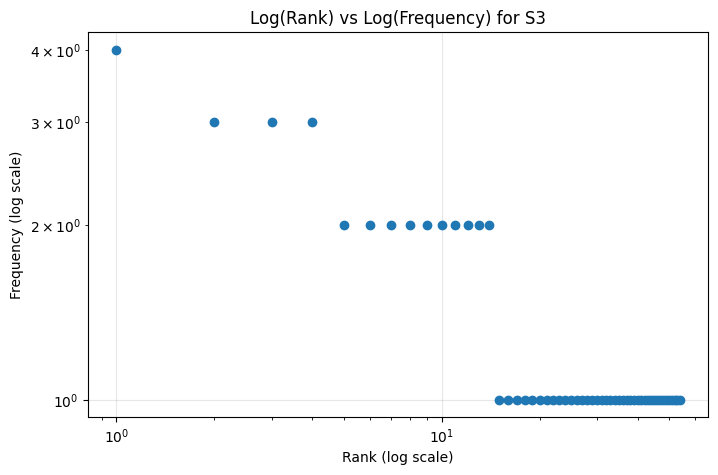


TOP 5 BIGRAMS IN S1
('.', 'the'): 4
('.', 'i'): 4
('while', 'uploading'): 3
('uploading', 'the'): 3
('the', 'file'): 3

TOP 5 BIGRAMS IN S3
('uploading', 'file'): 3
('ca', "n't"): 2
("n't", 'open'): 2
('student', 'portal'): 2
('please', 'resolve'): 2


In [ ]:

from collections import Counter
from nltk.stem import PorterStemmer
from nltk.util import ngrams
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
processed = [
    process_ticket(text)
    for text in df["Ticket_Text"]
]
S1 = [
    token
    for result in processed
    for token in result["tokens"]
]
S2 = [
    token for token in S1
    if not is_punct(token)
]
S3 = [
    token
    for result in processed
    for token in result["final"]
]
porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]
def get_stats(name, corpus):
    total = len(corpus)
    unique = len(set(corpus))

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(unique / total, 4) if total else 0
    }


stats = pd.DataFrame([
    get_stats("S1 - All tokens", S1),
    get_stats("S2 - No punctuation", S2),
    get_stats("S3 - Final tokens", S3),
    get_stats("S4 - Porter stemmed", S4)
])

print("CORPUS STATISTICS")
display(stats)
print("\nTOP 10 TOKENS IN S1")
for word, count in Counter(S1).most_common(10):
    print(f"{word}: {count}")

print("\nTOP 10 TOKENS IN S3")
for word, count in Counter(S3).most_common(10):
    print(f"{word}: {count}")
freq = Counter(S3).most_common()

if freq:
    ranks = np.arange(1, len(freq) + 1)
    frequencies = np.array([count for word, count in freq])

    plt.figure(figsize=(8, 5))
    plt.plot(ranks, frequencies, marker="o", linestyle="none")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Rank (log scale)")
    plt.ylabel("Frequency (log scale)")
    plt.title("Log(Rank) vs Log(Frequency) for S3")
    plt.grid(True, alpha=0.3)
    plt.show()
print("\nTOP 5 BIGRAMS IN S1")
for bigram, count in Counter(ngrams(S1, 2)).most_common(5):
    print(f"{bigram}: {count}")

print("\nTOP 5 BIGRAMS IN S3")
for bigram, count in Counter(ngrams(S3, 2)).most_common(5):
    print(f"{bigram}: {count}")


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR changes from S1 to S4 because each preprocessing step changes the total number of tokens and the number of unique tokens. S1 includes punctuation, while S2 removes punctuation. S3 removes punctuation and stopwords through the official preprocessing pipeline. S4 applies Porter stemming, which combines related word forms into common stems. This often reduces the number of unique tokens. However, TTR may increase or decrease depending on how the total and unique token counts change in my dataset.
